# EMA sabit noktalı modeli, adım adım inceleme

`ema_fixed.py`, `ema_float.py` ile aynı özyinelemeyi çalıştırır, ama `qformat.py`'nin nicemleme/doyum (quantize/saturate) fonksiyonlarından açık bir bit genişliğinde geçirir. Giriş/çıkış `Q(int_bits).(frac_bits)` formatındadır; biriktirici (accumulator) daha geniş tutulur, `frac_bits + guard_bits` kesirli bitle, ve sadece çıkışta doğal genişliğe yuvarlanır.

Bu defter, CLAUDE.md'nin işaret ettiği donanım sorununu birebir yeniden üretir: uzun bir tau ve yüksek bir örnekleme hızında alpha çok küçülür ve biriktirici ek hassasiyet taşımazsa filtrenin çıkışı hiç kımıldamaz.

In [1]:
import sys
sys.path.insert(0, '../models')

import numpy as np
import matplotlib.pyplot as plt
from ema_float import alpha_from_tau, ema_filter
from ema_fixed import ema_filter_fixed, required_guard_bits

## Duraksama: 1 MSa/s'de tau=1 s

$\alpha = 1 - e^{-T_s/\tau}$ burada yaklaşık $10^{-6}$ çıkar. 15 kesirli bit ve hiç koruma biti olmadan (`guard_bits=0`), gösterilebilen en küçük adım $2^{-15} \approx 3 \times 10^{-5}$ olur - $\alpha \cdot \mathrm{diff}$'in ulaşabildiği her değerden çok daha büyük, çünkü bu formatta $\mathrm{diff}$ kabaca $[-2,\ 2]$ ile sınırlıdır. Her artış sıfıra yuvarlanır.

alpha = 1.000e-06


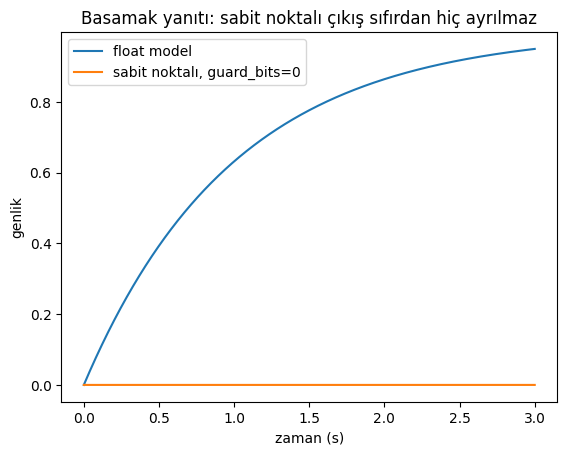

In [2]:
Ts = 1e-6
tau = 1.0
alpha = alpha_from_tau(tau, Ts)
print(f'alpha = {alpha:.3e}')

n_samples = 3_000_000  # 1 MSa/s'de birkaç tau
x = np.ones(n_samples)
t = np.arange(n_samples) * Ts

y_float = ema_filter(x, alpha)
y_stalled = ema_filter_fixed(x, alpha, int_bits=1, frac_bits=15, guard_bits=0)

plt.plot(t, y_float, label='float model')
plt.plot(t, y_stalled, label='sabit noktalı, guard_bits=0')
plt.xlabel('zaman (s)')
plt.ylabel('genlik')
plt.legend()
plt.title('Basamak yanıtı: sabit noktalı çıkış sıfırdan hiç ayrılmaz')
plt.show()

## Çözüm: yeterli koruma biti

Saf çözüm, "*ilk* artışın sıfıra yuvarlanmayacağı kadar koruma biti" koymaktır. Bu yetmez: $y$, $x$'e yaklaştıkça $\mathrm{diff} = x - y$ küçülmeye devam eder, dolayısıyla $\alpha \cdot \mathrm{diff}$ de küçülür ve yakınsamanın bir yerinde yine sıfıra yuvarlanır (underflow) - filtre gerçek son değerde değil, o anki değerde duraksar. `required_guard_bits` bunu doğru hesaplar: filtrenin, $\mathrm{diff}$ bir *çıkış* LSB'sinin içine inene kadar ilerlemeye devam etmesi için biriktiriciyi boyutlandırır; çünkü bundan daha ince bir şey çıkışta zaten görünmez.

gereken guard_bits = 20 (biriktirici: Q1.35)


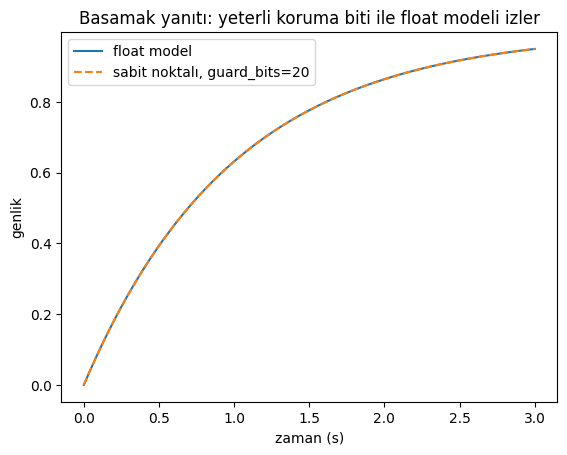

float modele göre en büyük hata: 4.30e-05


In [3]:
frac_bits = 15
guard_bits = required_guard_bits(alpha, frac_bits)
print(f'gereken guard_bits = {guard_bits} (biriktirici: Q1.{frac_bits + guard_bits})')

y_fixed = ema_filter_fixed(x, alpha, int_bits=1, frac_bits=frac_bits, guard_bits=guard_bits)

plt.plot(t, y_float, label='float model')
plt.plot(t, y_fixed, '--', label=f'sabit noktalı, guard_bits={guard_bits}')
plt.xlabel('zaman (s)')
plt.ylabel('genlik')
plt.legend()
plt.title('Basamak yanıtı: yeterli koruma biti ile float modeli izler')
plt.show()

print(f'float modele göre en büyük hata: {np.max(np.abs(np.array(y_fixed) - y_float)):.2e}')